In [ ]:
import argparse
import logging
import time
from utils.database import Database

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import scipy.stats as stats
from typing import List, Literal, Optional, Union, get_args, Dict
from helper import STEERING_TYPE_ENUM, format_time, DATA_TYPE_ENUM
from scipy.stats import pointbiserialr

In [2]:
DATABASE_NAME = "data_qwen_filtered_sent_new_new.sqlite"
database = Database(DATABASE_NAME)
database.create_database()

In [3]:
group_names = database.get_groups(
    [
            "sfam_train",
            "sfam_val",
            "sfam_test",
            "lisa_train",
            "lisa_val",
            "lisa_test"
        ]
)
group_names

['aviation',
 'biology',
 'chemistry',
 'cs',
 'electronics',
 'gamedev',
 'history',
 'philosophy',
 'physics',
 'politics',
 'softwareengineering']

In [4]:
STYLE_EMBEDDING_VECTOR = "style_vector_lisa"
GROUP_STEERING_NAMES = {
    "astronomy": "astronomers",
    "aviation": "pilots",
    "biology": "biologists",
    "chemistry": "chemists",
    "crypto": "cryptographers",
    "cs": "computer scientists",
    "datascience": "data scientists",
    "electronics": "electrical engineers",
    "gamedev": "game developers",
    "history": "historians",
    "law": "lawyers",
    "mechanics": "mechanical engineers",
    "philosophy": "philosophers",
    "physics": "physicists",
    "politics": "politicians",
    "softwareengineering": "software engineers",
}

In [5]:
answers = database.get_answers(
        [
            "sfam_train",
            "sfam_val",
            "sfam_test",
            "lisa_train",
            "lisa_val",
            "lisa_test"
        ]
    )
answers

,id,answer,style_vector_data,style_vector_similarity,style_vector_sfam,style_vector_lisa,style_embedding,normal_embedding,data_type,data_group
0,9301,One reason that comes to mind is as you get cl...,None,None,"[0.8203125, 0.80859375, 0.8359375, 0.80859375,...","[0.7734375, 0.87109375, 0.76171875, 0.79296875...","[0.2550148, -0.30052382, 0.11561787, -0.040354...","[0.0051232902, -0.016295647, -0.009886523, -0....",lisa_test,aviation
1,9302,"""Flying"" is the easy part. I've heard pilots s...",None,None,"[0.030273438, 0.19824219, 0.04345703, 0.371093...","[0.07910156, 0.36132812, 0.20214844, 0.4335937...","[0.16829948, -0.4188752, 0.20496449, -0.044716...","[0.015322763, 0.0098332325, 0.009868439, -0.00...",lisa_test,aviation
2,9303,Everything has been developed already. Geostat...,None,None,"[0.16308594, 0.62890625, 0.1328125, 0.7265625,...","[0.14257812, 0.41015625, 0.38867188, 0.6054687...","[0.0649766, -0.49878246, 0.2957327, -0.0016823...","[0.018963756, 0.0144625995, -0.007735893, -0.0...",lisa_test,aviation
3,9304,"First, let's be crystal clear on something: A ...",None,None,"[0.359375, 0.83984375, 0.8359375, 0.78515625, ...","[0.37890625, 0.79296875, 0.63671875, 0.7617187...","[0.023068864, -0.3144417, 0.15382598, -0.11889...","[0.011300983, 0.007992008, 0.0006451644, 0.018...",lisa_test,aviation
4,9305,"So if you are well rested and not ill, but sti...",None,None,"[0.8046875, 0.87890625, 0.890625, 0.87109375, ...","[0.73046875, 0.890625, 0.89453125, 0.90234375,...","[-0.06427705, 0.042348765, -0.13625436, -0.188...","[0.03018685, -0.0013303363, 0.016268976, 0.021...",lisa_test,aviation
...,...,...,...,...,...,...,...,...,...,...
65995,63946,One way to implement this would be to keep a s...,"[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...","[0.61328936, 0.58043784, 0.5049368, 0.5071499,...","[0.27734375, 0.47851562, 0.84765625, 0.8046875...","[0.25195312, 0.52734375, 0.671875, 0.78515625,...","[0.561646, -0.2670116, 0.04176686, -0.04766024...","[0.01202463, -0.012729334, -0.0060354527, -0.0...",sfam_val,softwareengineering
65996,63947,You can do this if you want whitespace to be a...,"[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...","[0.68546486, 0.6446781, 0.55577207, 0.57072467...","[0.90234375, 0.88671875, 0.91796875, 0.9257812...","[0.77734375, 0.70703125, 0.92578125, 0.9023437...","[0.4538733, -0.029214395, 0.03570223, -0.14966...","[0.033777792, 0.0024706689, -0.023419466, 0.00...",sfam_val,softwareengineering
65997,63948,"I have not read the article, but I have seen t...","[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, ...","[0.6573951, 0.6089434, 0.5355711, 0.5544891, 0...","[0.91796875, 0.91796875, 0.92578125, 0.9179687...","[0.9609375, 0.94140625, 0.921875, 0.86328125, ...","[0.52278614, 0.121209696, 0.08222238, -0.18985...","[0.016308283, 0.006665325, -0.01052792, 0.0121...",sfam_val,softwareengineering
65998,63949,"In addition to Chloe's excellent answer, I wou...","[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, ...","[0.6555527, 0.617773, 0.53646237, 0.54986084, ...","[0.8125, 0.875, 0.890625, 0.859375, 0.90234375...","[0.77734375, 0.92578125, 0.88671875, 0.8984375...","[0.5716052, -0.2407322, 0.09371007, -0.0729438...","[0.018528212, -0.011555733, -0.031172711, -0.0...",sfam_val,softwareengineering


In [6]:
answers = answers[answers[STYLE_EMBEDDING_VECTOR].notnull()]
answers = answers[answers["data_group"].isin(group_names)]
answers

,id,answer,style_vector_data,style_vector_similarity,style_vector_sfam,style_vector_lisa,style_embedding,normal_embedding,data_type,data_group
0,9301,One reason that comes to mind is as you get cl...,None,None,"[0.8203125, 0.80859375, 0.8359375, 0.80859375,...","[0.7734375, 0.87109375, 0.76171875, 0.79296875...","[0.2550148, -0.30052382, 0.11561787, -0.040354...","[0.0051232902, -0.016295647, -0.009886523, -0....",lisa_test,aviation
1,9302,"""Flying"" is the easy part. I've heard pilots s...",None,None,"[0.030273438, 0.19824219, 0.04345703, 0.371093...","[0.07910156, 0.36132812, 0.20214844, 0.4335937...","[0.16829948, -0.4188752, 0.20496449, -0.044716...","[0.015322763, 0.0098332325, 0.009868439, -0.00...",lisa_test,aviation
2,9303,Everything has been developed already. Geostat...,None,None,"[0.16308594, 0.62890625, 0.1328125, 0.7265625,...","[0.14257812, 0.41015625, 0.38867188, 0.6054687...","[0.0649766, -0.49878246, 0.2957327, -0.0016823...","[0.018963756, 0.0144625995, -0.007735893, -0.0...",lisa_test,aviation
3,9304,"First, let's be crystal clear on something: A ...",None,None,"[0.359375, 0.83984375, 0.8359375, 0.78515625, ...","[0.37890625, 0.79296875, 0.63671875, 0.7617187...","[0.023068864, -0.3144417, 0.15382598, -0.11889...","[0.011300983, 0.007992008, 0.0006451644, 0.018...",lisa_test,aviation
4,9305,"So if you are well rested and not ill, but sti...",None,None,"[0.8046875, 0.87890625, 0.890625, 0.87109375, ...","[0.73046875, 0.890625, 0.89453125, 0.90234375,...","[-0.06427705, 0.042348765, -0.13625436, -0.188...","[0.03018685, -0.0013303363, 0.016268976, 0.021...",lisa_test,aviation
...,...,...,...,...,...,...,...,...,...,...
65995,63946,One way to implement this would be to keep a s...,"[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...","[0.61328936, 0.58043784, 0.5049368, 0.5071499,...","[0.27734375, 0.47851562, 0.84765625, 0.8046875...","[0.25195312, 0.52734375, 0.671875, 0.78515625,...","[0.561646, -0.2670116, 0.04176686, -0.04766024...","[0.01202463, -0.012729334, -0.0060354527, -0.0...",sfam_val,softwareengineering
65996,63947,You can do this if you want whitespace to be a...,"[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, ...","[0.68546486, 0.6446781, 0.55577207, 0.57072467...","[0.90234375, 0.88671875, 0.91796875, 0.9257812...","[0.77734375, 0.70703125, 0.92578125, 0.9023437...","[0.4538733, -0.029214395, 0.03570223, -0.14966...","[0.033777792, 0.0024706689, -0.023419466, 0.00...",sfam_val,softwareengineering
65997,63948,"I have not read the article, but I have seen t...","[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, ...","[0.6573951, 0.6089434, 0.5355711, 0.5544891, 0...","[0.91796875, 0.91796875, 0.92578125, 0.9179687...","[0.9609375, 0.94140625, 0.921875, 0.86328125, ...","[0.52278614, 0.121209696, 0.08222238, -0.18985...","[0.016308283, 0.006665325, -0.01052792, 0.0121...",sfam_val,softwareengineering
65998,63949,"In addition to Chloe's excellent answer, I wou...","[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, ...","[0.6555527, 0.617773, 0.53646237, 0.54986084, ...","[0.8125, 0.875, 0.890625, 0.859375, 0.90234375...","[0.77734375, 0.92578125, 0.88671875, 0.8984375...","[0.5716052, -0.2407322, 0.09371007, -0.0729438...","[0.018528212, -0.011555733, -0.031172711, -0.0...",sfam_val,softwareengineering


In [7]:
answers[STYLE_EMBEDDING_VECTOR]

0        [0.7734375, 0.87109375, 0.76171875, 0.79296875...
1        [0.07910156, 0.36132812, 0.20214844, 0.4335937...
2        [0.14257812, 0.41015625, 0.38867188, 0.6054687...
3        [0.37890625, 0.79296875, 0.63671875, 0.7617187...
4        [0.73046875, 0.890625, 0.89453125, 0.90234375,...
                               ...                        
65995    [0.25195312, 0.52734375, 0.671875, 0.78515625,...
65996    [0.77734375, 0.70703125, 0.92578125, 0.9023437...
65997    [0.9609375, 0.94140625, 0.921875, 0.86328125, ...
65998    [0.77734375, 0.92578125, 0.88671875, 0.8984375...
65999    [0.043945312, 0.13574219, 0.14355469, 0.349609...
Name: style_vector_lisa, Length: 66000, dtype: object

In [8]:
style_vector_df = database.get_style_vector()
style_vector_df

,style_vector_index,id,style_sentence,embedding,prompt_type
0,0,68435,The author's language is poetic.,"[0.020838663, -0.019563107, 0.026418751, -0.01...",Style prompt
1,1,7390,The author uses sarcasm.,"[0.016749486, -0.0016283798, 0.022112817, -0.0...",Style prompt
2,2,508636,The author's sentence is a fragment.,"[0.021339525, -0.004190294, 0.02056036, -0.020...",Style prompt
3,3,3684,The author uses run-on sentences.,"[0.02296366, -0.0018667094, -0.010151177, -0.0...",Style prompt
4,4,770,The author uses active voice.,"[0.0009956212, 0.008551453, 0.010529343, -0.00...",Style prompt
...,...,...,...,...,...
1245,1245,288963,The author contrasts and connects different as...,"[0.009257467, -0.0019067725, 0.0033803377, -0....",Style prompt
1246,1246,296067,The author uses punctuation to make it easier ...,"[0.00996561, -0.0024122468, 0.0035936725, -0.0...",Style prompt
1247,1247,805820,The author describes interactions without conf...,"[0.012834309, 0.0016888599, -0.022803647, -0.0...",Style prompt
1248,1248,302154,The author uses contractions in formal contexts.,"[0.034999542, 0.00016702714, -0.016780388, -0....",Style prompt


In [9]:
def _get_most_important_attributes(
    style_vectors: np.ndarray, groups: np.ndarray
) -> Dict[str, Dict[str, np.ndarray]]:
    """
    Compute the most important attributes for each group using point-biserial correlation.

    Args:
        style_vectors (np.ndarray): The style vectors of the samples.
        groups (np.ndarray): The group labels for each sample.
    Returns:
        Dict[str, Dict[str, np.ndarray]]: A dictionary where the keys are group names and the values are dictionaries
            containing the indices of the dimensions ordered by importance and their corresponding correlation coefficients.
    """
    unique_groups = np.unique(groups)
    most_important_dims = {}

    # Loop over each group
    for group in unique_groups:
        # Create a binary indicator: 1 if the sample belongs to the current group, 0 otherwise.
        binary_labels = (groups == group).astype(int)

        # Initialize an array to store correlation coefficients for each dimension
        corr_coeffs = np.zeros(style_vectors.shape[1])

        # Compute the point-biserial correlation for each dimension
        for i in range(style_vectors.shape[1]):
            corr, _ = pointbiserialr(style_vectors[:, i], binary_labels)
            corr_coeffs[i] = corr  # correlation for dimension i

        top_dims = np.argsort(corr_coeffs)[::-1]
        top_corrs = corr_coeffs[top_dims]

        most_important_dims[group] = {"dimensions": top_dims, "correlations": top_corrs}

    return most_important_dims

In [10]:
most_important_attribute_indeces = _get_most_important_attributes(
    np.array(answers[STYLE_EMBEDDING_VECTOR].values.tolist()),
    answers["data_group"].values,
)

In [11]:
most_important_attribute_indeces

{'aviation': {'dimensions': array([ 361,  566,  424, ...,  860, 1028,  512], shape=(1250,)),
  'correlations': array([ 0.83833335,  0.83137603,  0.8192683 , ..., -0.31811239,
         -0.32635987, -0.36574006], shape=(1250,))},
 'biology': {'dimensions': array([314, 671, 745, ...,  15, 238, 692], shape=(1250,)),
  'correlations': array([ 0.79292535,  0.75154279,  0.72765474, ..., -0.2133963 ,
         -0.23518922, -0.26579244], shape=(1250,))},
 'chemistry': {'dimensions': array([ 957,  322,  388, ..., 1235, 1007,  692], shape=(1250,)),
  'correlations': array([ 0.74943993,  0.71961971,  0.7149381 , ..., -0.28940183,
         -0.29244922, -0.29385399], shape=(1250,))},
 'cs': {'dimensions': array([908, 231, 793, ...,  87, 292, 104], shape=(1250,)),
  'correlations': array([ 0.61503428,  0.6072139 ,  0.59854129, ..., -0.21566926,
         -0.22579244, -0.24077395], shape=(1250,))},
 'electronics': {'dimensions': array([ 394,  340,  142, ..., 1165, 1148,    4], shape=(1250,)),
  'correla

In [12]:
groups = []
style_attributes_list = []
knowledge_attributes_list = []

mean_group_profiles = {}
group_vector_series = answers.groupby("data_group")[STYLE_EMBEDDING_VECTOR].apply(list)
for group, group_vectors in group_vector_series.items():
    mean_group_profiles[group] = np.mean(group_vectors, axis=0)

for group in group_names:
    # check if the group is in the steering names
    # not because it is needed, but too ensure that all steering is skipped if it is not included
    pretty_group_name = GROUP_STEERING_NAMES.get(group, None)
    if pretty_group_name is None:
        logger.error(
            f"Skipping attribute steering for group {group} as it is not in GROUP_STEERING_NAMES"
        )
        continue
    if group not in most_important_attribute_indeces:
        logger.error(
            f"There is no data to extract the most important attributes for the group {group}"
        )
        continue

    attribute_indeces = most_important_attribute_indeces[group]["dimensions"]
    attributes_correlations = most_important_attribute_indeces[group]["correlations"]    
    
    # Get the most important attributes
    style_vector_data = style_vector_df.values
    group_style_vector = pd.DataFrame(
        style_vector_data[attribute_indeces],
        style_vector_df.index[attribute_indeces],
        style_vector_df.columns,
    )

    # Get profiles = mean vectors
    mean_series = pd.Series(
        data=mean_group_profiles[group][attribute_indeces],
        index=style_vector_df.index[attribute_indeces],
        name="mean"
    )
    
    # Create a Series for correlations indexed by attribute indices
    correlation_series = pd.Series(
        data=attributes_correlations,
        index=style_vector_df.index[attribute_indeces],
        name="correlation"
    )

    # Add the correlation and mean column to group_style_vector
    group_style_vector = group_style_vector.join(mean_series)
    group_style_vector = group_style_vector.join(correlation_series)
    group_style_vector = group_style_vector.sort_index()

    style_attributes_df = group_style_vector[group_style_vector["prompt_type"] == "Style prompt"]#.head(50)
    knowledge_attributes_df = group_style_vector[group_style_vector["prompt_type"] == "Knowledge prompt"]#.head(50)

    groups.append(group)
    style_attributes_list.append(style_attributes_df)
    knowledge_attributes_list.append(knowledge_attributes_df)

In [128]:
sentences = []

In [129]:
# Loop through all groups and collect point-biserial correlation values for each style sentence
for group, style_df in zip(groups, style_attributes_list):
    print(f"Style attributes for group {GROUP_STEERING_NAMES[group]}:")
    # Create a dictionary: {style_sentence: correlation}
    count = 0
    for index, row in style_df.iterrows():
        print(row['style_sentence'], row['correlation'])
        sentences.append(row['style_sentence'])
        count += 1
        if count > 9:
            break
    print()

Style attributes for group pilots:
The author uses technical aviation terms. 0.5418415174543623
The author uses regulatory language. 0.2097617696340302
The author refers to pilots without using gender-specific terms. 0.14089896571773008
The author emphasizes coordination. 0.08108263971817775
The author uses altitude descriptions. 0.08009689528080902
The author uses words related to money. 0.06980238371026722
The author capitalizes acronyms correctly. 0.05922947597307708
The author uses words related to time. 0.05723377662301526
The author uses words related to attention. 0.05609469336307783
The author uses terminology related to deceased individuals. 0.042644020176460004

Style attributes for group biologists:
The author uses medical terminology. 0.3137494514271116
The author uses mutations. 0.15324307385323038
The author uses technical terms from genetic and molecular biology. 0.13496272169648593
The author uses physiological descriptions. 0.12011682230987251
The author conveys comple

In [130]:
# Loop through all groups and collect point-biserial correlation values for each knowledge sentence
for group, knowledge_df in zip(groups, knowledge_attributes_list):
    print(f"Knowledge attributes for group {GROUP_STEERING_NAMES[group]}:")
    # Create a dictionary: {style_sentence: correlation}
    count = 0
    for index, row in knowledge_df.iterrows():
        print(row['style_sentence'], row['correlation'])
        sentences.append(row['style_sentence'])
        count += 1
        if count > 9:
            break
    print()

Knowledge attributes for group pilots:
The author understands aerodynamics. 0.5925323235948077
The author knows about the relationship between airline operations and safety regulations. 0.536482912531568
The author understands pilots must be adaptable. 0.3667596243792536
The author understands fuel efficiency. 0.30775117272518315
The author knows modern aircraft systems are sophisticated. 0.30289126640769126
The author knows passenger comfort is important. 0.2566822899037244
The author knows pre-flight planning is important. 0.25306899420513035
The author understands emergency procedures. 0.22578247797275666
The author knows quick decision-making is essential. 0.21800113220346556
The author understands weight considerations. 0.19168711905838431

Knowledge attributes for group biologists:
The author understands evolutionary biology. 0.42384077886447186
The author understands metabolic pathways. 0.24180333771846485
The author understands environmental and genetic factors interact. 0.2170

In [ ]:
desired_group_order = ["biology", "chemistry", "physics", "aviation", "electronics", "cs", "softwareengineering", "gamedev", "politics", "history", "philosophy"]  # your exact group order list

heatmap_style_data = {}

# Loop through all groups and collect point-biserial correlation values for each style sentence
for group, style_df in zip(groups, style_attributes_list):
    # Create a dictionary: {style_sentence: correlation}
    group_dict = dict(zip(style_df['style_sentence'], style_df['mean']))
    heatmap_style_data[group] = group_dict

heatmap_style_df = pd.DataFrame(heatmap_style_data).T

heatmap_style_df = heatmap_style_df.reindex(desired_group_order)

heatmap_knowledge_data = {}

# Loop through all groups and collect correlation values for each knowledge sentence
for group, knowledge_df in zip(groups, knowledge_attributes_list):
    # Create a dictionary: {style_sentence: correlation}
    group_dict = dict(zip(knowledge_df['style_sentence'], knowledge_df['mean']))
    heatmap_knowledge_data[group] = group_dict

heatmap_knowledge_df = pd.DataFrame(heatmap_knowledge_data).T

heatmap_knowledge_df = heatmap_knowledge_df.reindex(desired_group_order)

# Compute Pearson correlation matrices
style_corr = heatmap_style_df.T.corr()
knowledge_corr = heatmap_knowledge_df.T.corr()

# Optional: Compute p-values for significance
def compute_pvals(df):
    groups = df.index
    pvals = pd.DataFrame(np.ones((len(groups), len(groups))), index=groups, columns=groups)
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            r, p = stats.pearsonr(df.loc[groups[i]], df.loc[groups[j]])
            pvals.iloc[i, j] = p
            pvals.iloc[j, i] = p
    return pvals

style_pvals = compute_pvals(heatmap_style_df)
knowledge_pvals = compute_pvals(heatmap_knowledge_df)

# Create combined correlation matrix: upper = knowledge, lower = style
combined_corr = style_corr.copy()
for i in range(len(desired_group_order)):
    for j in range(len(desired_group_order)):
        if i < j:  # upper triangle -> knowledge
            combined_corr.iloc[i, j] = knowledge_corr.iloc[i, j]
        elif i == j:  # diagonal
            combined_corr.iloc[i, j] = 1  # set diagonal to 1
        # lower triangle remains style

# Plot
plt.figure(figsize=(4.4, 5))
ax = sns.heatmap(combined_corr, cmap='coolwarm', annot=False, cbar=True, linewidths=0.5, cbar_kws = dict(use_gridspec=True,location="bottom",pad=0.17), vmin=-1, vmax=1)

# Add bold numbers for significance + special formatting for diagonal
for i in range(len(desired_group_order)):
    for j in range(len(desired_group_order)):
        val = combined_corr.iloc[i, j]        

        # Off-diagonal: bold significant correlations
        p_val = style_pvals.iloc[i, j] if i > j else knowledge_pvals.iloc[i, j]
        if p_val < 0.05:
            text = ax.text(
                j + 0.5,
                i + 0.5,
                f"*",
                ha='center',
                va='center',
                color='black'
            )
            if val > 0.7 or val < -0.7:
                text.set_color("white")
            #text.set_weight("bold")

GROUP_STEERING_NAMES = {
    "astronomy": "astronomers",
    "aviation": "pilots",
    "biology": "biologists",
    "chemistry": "chemists",
    "crypto": "cryptographers",
    "cs": "computer\nscientists",
    "datascience": "data scientists",
    "electronics": "electrical\nengineers",
    "gamedev": "game\ndevelopers",
    "history": "historians",
    "law": "lawyers",
    "mechanics": "mechanical\nengineers",
    "philosophy": "philo-\nsophers",
    "physics": "physicists",
    "politics": "politicians",
    "softwareengineering": "software\nengineers",
}

desired_group_order_steering_names = [GROUP_STEERING_NAMES[group] for group in desired_group_order]
                
# Labels and title
#plt.title("Combined Pearson Correlation Between Groups\nUpper = Knowledge, Lower = Style (bold = p < 0.05)")

plt.xticks(
    np.arange(len(desired_group_order_steering_names)) + 0.5,
    desired_group_order_steering_names,
    rotation=55,
    ha='right',
    fontsize=8.2  # increase the number to make it bigger
)

plt.yticks(
    np.arange(len(desired_group_order_steering_names)) + 0.5,
    desired_group_order_steering_names,
    rotation=0,
    fontsize=8.2  # increase the number to make it bigger
)
plt.tight_layout()

# Save to PDF
plt.savefig("group-attribute-correlation.pdf", format="pdf", bbox_inches="tight")

plt.show()


# Plot
plt.figure(figsize=(5, 5))
ax = sns.heatmap(combined_corr, cmap='coolwarm', annot=False, cbar=False, linewidths=0.5, vmin=-1, vmax=1)



# Add bold numbers for significance + special formatting for diagonal
for i in range(len(desired_group_order)):
    for j in range(len(desired_group_order)):
        val = combined_corr.iloc[i, j]

        val_formatted = f"{val:.2f}"
        if val_formatted.startswith("0"):
            val_formatted = val_formatted[1:]  # remove leading zero
        elif val_formatted.startswith("-0"):
            val_formatted = "-" + val_formatted[2:]  # keep minus, remove zero
        elif val_formatted.startswith("1"):
            val_formatted = f"{val:.1f}"
        # Default annotation
        text = ax.text(
            j + 0.5,
            i + 0.5,
            val_formatted,
            ha='center',
            va='center',
            color='black'
        )

        # Special case: diagonal → bold + white text
        if i == j:
            text.set_weight("bold")
            text.set_color("white")
            continue  # no need to check significance
            
        if val >= 0.65 or val <= -0.75:
            text.set_color("white")

        # Off-diagonal: bold significant correlations
        p_val = style_pvals.iloc[i, j] if i > j else knowledge_pvals.iloc[i, j]
        if p_val < 0.05:
            text.set_weight("bold")

GROUP_STEERING_NAMES = {
    "astronomy": "astronomers",
    "aviation": "pilots",
    "biology": "biologists",
    "chemistry": "chemists",
    "crypto": "cryptographers",
    "cs": "computer\nscientists",
    "datascience": "data scientists",
    "electronics": "electrical\nengineers",
    "gamedev": "game\ndevelopers",
    "history": "historians",
    "law": "lawyers",
    "mechanics": "mechanical\nengineers",
    "philosophy": "philo-\nsophers",
    "physics": "physicists",
    "politics": "politicians",
    "softwareengineering": "software\nengineers",
}

desired_group_order_steering_names = [GROUP_STEERING_NAMES[group] for group in desired_group_order]
                
# Labels and title
#plt.title("Combined Pearson Correlation Between Groups\nUpper = Knowledge, Lower = Style (bold = p < 0.05)")

plt.xticks(
    np.arange(len(desired_group_order_steering_names)) + 0.5,
    desired_group_order_steering_names,
    rotation=55,
    ha='right',
    fontsize=10  # increase the number to make it bigger
)

plt.yticks(
    np.arange(len(desired_group_order_steering_names)) + 0.5,
    desired_group_order_steering_names,
    rotation=0,
    fontsize=10  # increase the number to make it bigger
)
plt.tight_layout()

# Save to PDF
plt.savefig("group-attribute-correlation-num.pdf", format="pdf", bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>




<Figure size 640x480 with 0 Axes>

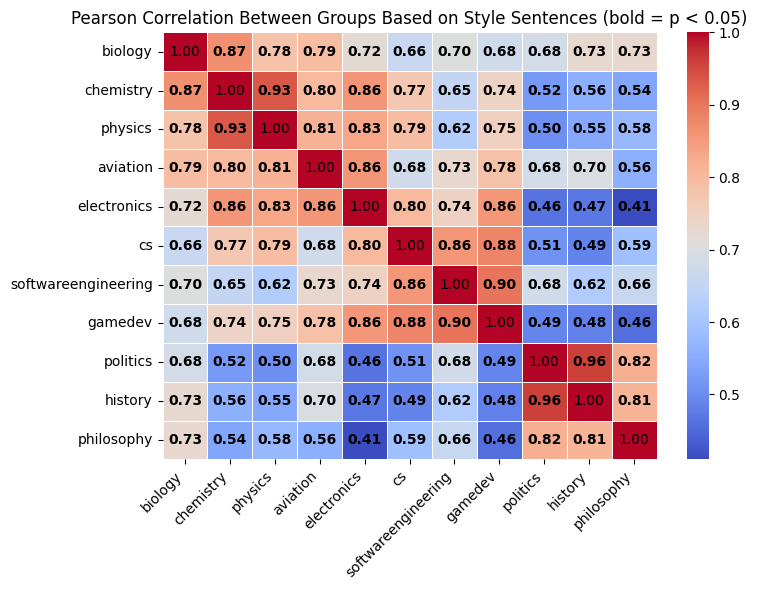

In [118]:
#groups, style_attributes_list, _ = steering.get_attributes()
# Style analaysis
heatmap_style_data = {}

# Loop through all groups and collect point-biserial correlation values for each style sentence
for group, style_df in zip(groups, style_attributes_list):
    # Create a dictionary: {style_sentence: correlation}
    group_dict = dict(zip(style_df['style_sentence'], style_df['mean']))
    heatmap_style_data[group] = group_dict

heatmap_style_df = pd.DataFrame(heatmap_style_data).T
    
# Optional: sort columns alphabetically or by mean correlation
heatmap_style_df = heatmap_style_df.sort_index(axis=1)  # sort columns (style_sentences)

desired_group_order = ["biology", "chemistry", "physics", "aviation", "electronics", "cs", "softwareengineering", "gamedev", "politics", "history", "philosophy"]  # your exact group order list
heatmap_style_df = heatmap_style_df.reindex(desired_group_order)

# Plot heatmap
plt.clf()
plt.figure(figsize=(400, len(heatmap_style_df) * 0.8))
sns.heatmap(heatmap_style_df, annot=True, cmap='YlGnBu', linewidths=0.5)
plt.xlabel('Style Sentence')
plt.ylabel('Group')
plt.title('Style Correlation Heatmap Across Groups')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.show()
plt.close()

# Step 1: Pearson correlation matrix
groups_new_order = heatmap_style_df.index
pearson_corr = heatmap_style_df.T.corr(method='pearson')

# Compute p-values
pvals = pd.DataFrame(np.ones_like(pearson_corr), index=groups_new_order, columns=groups_new_order)
for i in range(len(groups_new_order)):
    for j in range(i + 1, len(groups_new_order)):
        r, p = stats.pearsonr(heatmap_style_df.loc[groups_new_order[i]], heatmap_style_df.loc[groups_new_order[j]])
        pvals.iloc[i, j] = p
        pvals.iloc[j, i] = p

# Plot the heatmap without annotations
plt.clf()
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pearson_corr, cmap='coolwarm', linewidths=0.5, cbar=True)

# Manually add bold text for significant values
for i in range(len(groups_new_order)):
    for j in range(len(groups_new_order)):
        r_val = pearson_corr.iloc[i, j]
        p_val = pvals.iloc[i, j]
        text = ax.text(j + 0.5, i + 0.5, f"{r_val:.2f}",
                       ha='center', va='center', color='black')
        if p_val < 0.05 and i != j:
            text.set_weight("bold")  # Bold only if significant

# Labels and title
plt.title('Pearson Correlation Between Groups Based on Style Sentences (bold = p < 0.05)')
plt.xticks(np.arange(len(groups_new_order)) + 0.5, groups_new_order, rotation=45, ha='right')
plt.yticks(np.arange(len(groups_new_order)) + 0.5, groups_new_order, rotation=0)
plt.tight_layout()
plt.show()
plt.close()

<Figure size 640x480 with 0 Axes>




<Figure size 640x480 with 0 Axes>

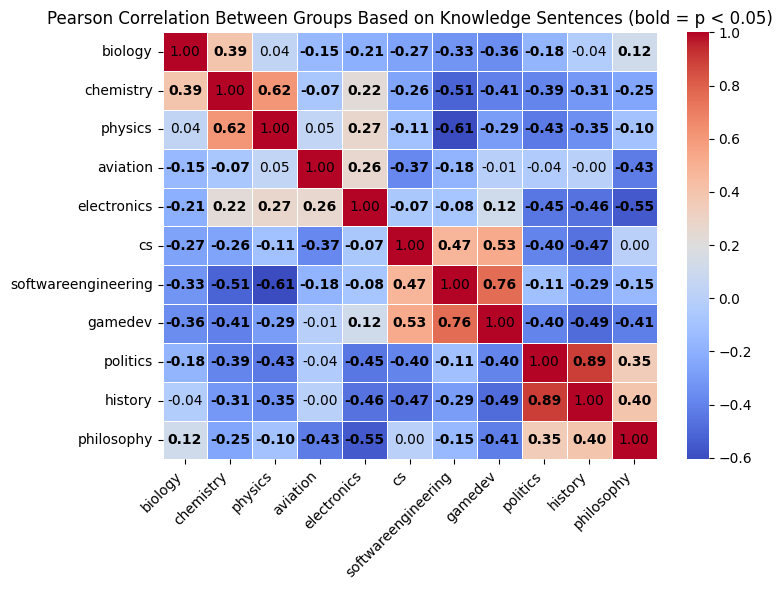

In [15]:
#groups, _, knowledge_attributes_list = steering.get_attributes()
# Background knowledge analysis
heatmap_knowledge_data = {}

# Loop through all groups and collect correlation values for each knowledge sentence
for group, knowledge_df in zip(groups, knowledge_attributes_list):
    # Create a dictionary: {style_sentence: correlation}
    group_dict = dict(zip(knowledge_df['style_sentence'], knowledge_df['correlation']))
    heatmap_knowledge_data[group] = group_dict

heatmap_knowlegde_df = pd.DataFrame(heatmap_knowledge_data).T
    
# Optional: sort columns alphabetically or by mean correlation
heatmap_knowlegde_df = heatmap_knowlegde_df.sort_index(axis=1)  # sort columns (style_sentences)
desired_group_order = ["biology", "chemistry", "physics", "aviation", "electronics", "cs", "softwareengineering", "gamedev", "politics", "history", "philosophy"]  # your exact group order list
heatmap_knowlegde_df = heatmap_knowlegde_df.reindex(desired_group_order)

# Plot heatmap
plt.clf()
plt.figure(figsize=(600, len(heatmap_knowlegde_df) * 0.8))
sns.heatmap(heatmap_knowlegde_df, annot=True, cmap='YlGnBu', linewidths=0.5)
plt.xlabel('Knowledge Sentence')
plt.ylabel('Group')
plt.title('Background knowledge Correlation Heatmap Across Groups')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
#plt.savefig("background_knowledge_heatmap.png", dpi=600)
plt.show()
plt.close()



# Step 1: Pearson correlation matrix
groups_new_order = heatmap_knowlegde_df.index
pearson_corr = heatmap_knowlegde_df.T.corr(method='pearson')

# Compute p-values
pvals = pd.DataFrame(np.ones_like(pearson_corr), index=groups_new_order, columns=groups_new_order)
for i in range(len(groups_new_order)):
    for j in range(i + 1, len(groups_new_order)):
        r, p = stats.pearsonr(heatmap_knowlegde_df.loc[groups_new_order[i]], heatmap_knowlegde_df.loc[groups_new_order[j]])
        pvals.iloc[i, j] = p
        pvals.iloc[j, i] = p

# Plot the heatmap without annotations
plt.clf()
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pearson_corr, cmap='coolwarm', linewidths=0.5, cbar=True)

# Manually add bold text for significant values
for i in range(len(groups_new_order)):
    for j in range(len(groups_new_order)):
        r_val = pearson_corr.iloc[i, j]
        p_val = pvals.iloc[i, j]
        text = ax.text(j + 0.5, i + 0.5, f"{r_val:.2f}",
                       ha='center', va='center', color='black')
        if p_val < 0.05 and i != j:
            text.set_weight("bold")  # Bold only if significant

# Labels and title
plt.title('Pearson Correlation Between Groups Based on Knowledge Sentences (bold = p < 0.05)')
plt.xticks(np.arange(len(groups_new_order)) + 0.5, groups_new_order, rotation=45, ha='right')
plt.yticks(np.arange(len(groups_new_order)) + 0.5, groups_new_order, rotation=0)
plt.tight_layout()
plt.show()
plt.close()